# Sensor Models — Range, Bearing, and Camera Projection (Simulation Notebook)
From the book *Bayesian Methods for Autonomous Robotics and Intelligent Infrastructure Systems* by Khalid M. Mosalam.

This notebook accompanies the **Sensor Models** chapter and demonstrates:

- **Range** and **bearing** measurements to a landmark in 2D  
- **Measurement noise** and likelihood evaluation  
- A simple **Gauss–Newton** position estimate from range+bearing  
- A basic **observability** check (Jacobian rank) for different measurement sets  
- A minimal **pinhole camera projection** example (3D → image plane)

Dependencies: `numpy`, `matplotlib`.
Run from this notebook directory to export the four main figures to `../figures/`. The two heatmap layers are rasterized at 300 dpi; axes, text, markers, and the iterate path remain vector. All observations are simulated.


Figure styling: Ziad Mosalam. Run all cells from this notebook directory. Each figure is displayed below its calculation and exported to `../figures/` as PDF and PNG. The original simulation and estimation calculations are unchanged.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

plt.style.use('book.mplstyle')
Path('../figures').mkdir(exist_ok=True)

BLUE = '#003262'
GOLD = '#B17A00'
TEAL = '#247C86'
INK = '#30363B'
GRAY = '#7D858B' 

np.random.seed(7)
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Arc, Rectangle

# A sequential scale: darker blue means a larger likelihood.
likelihood_colors = LinearSegmentedColormap.from_list(
    'book_likelihood', ['#FAFBFC', '#DCE6EF', '#7B9DBB', BLUE])

## 1) Geometry: range vs bearing in 2D

State (robot position):  
$\mathbf{x} = \begin{bmatrix}x \\ y\end{bmatrix}$

Landmark position:  
$\ell = \begin{bmatrix}\ell_x \\ \ell_y\end{bmatrix}$

Range model:
$z_r = \sqrt{(x-\ell_x)^2+(y-\ell_y)^2} + v_r$

Bearing model:
$z_\theta = \operatorname{atan2}(y-\ell_y,\,x-\ell_x) + v_\theta$

Note: $\mathrm{atan2}(y,x)$ returns the signed angle between the positive $x$-axis and the vector $(x,y)$, correctly resolving the quadrant and avoiding division-by-zero ambiguity.

In [2]:
def h_range(xy, ell):
    dx, dy = xy[0]-ell[0], xy[1]-ell[1]
    return np.sqrt(dx*dx + dy*dy)

def h_bearing(xy, ell):
    dx, dy = xy[0]-ell[0], xy[1]-ell[1]
    return np.arctan2(dy, dx)

def wrap_to_pi(a):
    return np.arctan2(np.sin(a), np.cos(a))

In [3]:
# Example setup
ell = np.array([2.0, 1.0])
x_true = np.array([5.0, 3.0])

sigma_r = 0.15          # meters
sigma_th = np.deg2rad(2.0)  # radians

z_r = h_range(x_true, ell) + np.random.randn()*sigma_r
z_th = wrap_to_pi(h_bearing(x_true, ell) + np.random.randn()*sigma_th)

z_r, z_th

(np.float64(3.8591301310340427), np.float64(0.5717383210995228))

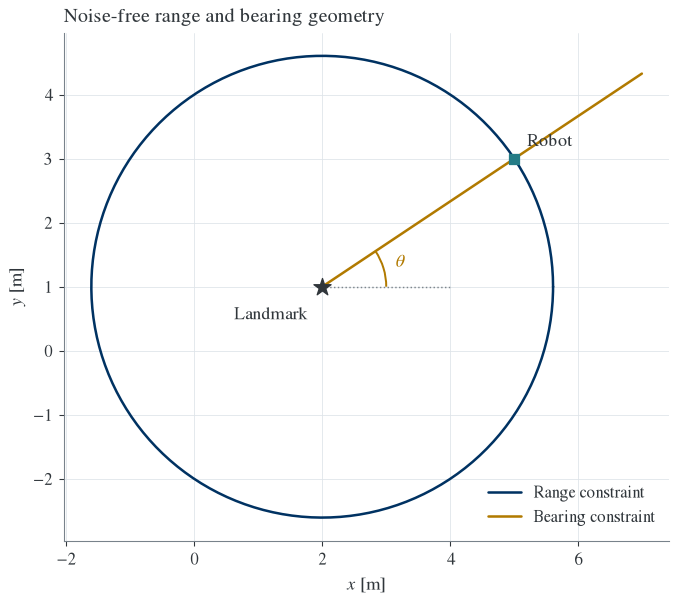

In [4]:
# Plot geometry without changing the example's noise-free constraints.
r0 = h_range(x_true, ell)
t = np.linspace(0, 2*np.pi, 300)
th0 = h_bearing(x_true, ell)

fig, ax = plt.subplots(figsize=(6.5, 4.6), layout='constrained')
ax.plot(ell[0] + r0*np.cos(t), ell[1] + r0*np.sin(t),
        color=BLUE, label='Range constraint')
ax.plot([ell[0], ell[0]+6*np.cos(th0)], [ell[1], ell[1]+6*np.sin(th0)],
        color=GOLD, label='Bearing constraint')
ax.plot([ell[0], ell[0]+2.0], [ell[1], ell[1]],
        color=GRAY, linestyle=':', linewidth=0.8)
ax.add_patch(Arc(ell, 2.0, 2.0, theta1=0, theta2=np.rad2deg(th0),
                 color=GOLD, linewidth=1.1))
ax.text(ell[0]+1.15, ell[1]+0.3, r'$\theta$', color=GOLD)
ax.scatter(*ell, marker='*', s=100, color=INK, zorder=5, label='Landmark')
ax.scatter(*x_true, marker='s', s=35, color=TEAL, zorder=5, label='Robot')
ax.annotate('Landmark', ell, xytext=(-8,-18), textcoords='offset points', ha='right')
ax.annotate('Robot', x_true, xytext=(7,7), textcoords='offset points')
ax.set(aspect='equal', xlabel='$x$ [m]', ylabel='$y$ [m]')
ax.set_title('Noise-free range and bearing geometry', loc='left')
ax.grid(linewidth=0.45)
ax.legend(handles=ax.get_legend_handles_labels()[0][:2],
          loc='lower right')
fig.savefig('../figures/sensor-models-geometry.pdf', bbox_inches='tight')
fig.savefig('../figures/sensor-models-geometry.png', dpi=240, bbox_inches='tight')
plt.show()

## 2) Likelihood of measurements

Assume independent Gaussian noises:

$ p(z_r|\mathbf{x}) \propto \exp\left(-\frac{(z_r-h_r(\mathbf{x}))^2}{2\sigma_r^2}\right),\qquad
p(z_\theta|\mathbf{x}) \propto \exp\left(-\frac{\mathrm{wrap}(z_\theta-h_\theta(\mathbf{x}))^2}{2\sigma_\theta^2}\right) $

In [5]:
def loglike_range(zr, xy, ell, sigma):
    e = zr - h_range(xy, ell)
    return -0.5*(e/sigma)**2

def loglike_bearing(zth, xy, ell, sigma):
    e = wrap_to_pi(zth - h_bearing(xy, ell))
    return -0.5*(e/sigma)**2

def loglike_joint(zr, zth, xy, ell, sig_r, sig_th):
    return loglike_range(zr, xy, ell, sig_r) + loglike_bearing(zth, xy, ell, sig_th)

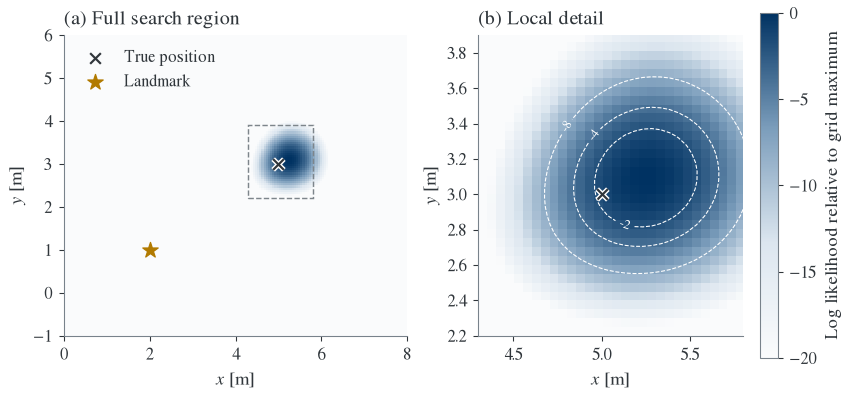

In [6]:
# Likelihood surface over a grid
xs = np.linspace(0, 8, 160)
ys = np.linspace(-1, 6, 140)
LL = np.zeros((len(ys), len(xs)))

for i, y in enumerate(ys):
    for j, x in enumerate(xs):
        LL[i, j] = loglike_joint(z_r, z_th, np.array([x, y]), ell, sigma_r, sigma_th)

# The right panel magnifies the same grid, with the same color limits.
fig, axes = plt.subplots(1, 2, figsize=(6.5, 3.4), layout='constrained',
                         gridspec_kw={'width_ratios':[1.295,1]})
for ax in axes:
    im = ax.pcolormesh(xs, ys, LL - LL.max(), shading='nearest',
                       cmap=likelihood_colors, rasterized=True, vmin=-20, vmax=0)
    ax.scatter(*x_true, color='white', marker='x', s=35, linewidth=2.8)
    ax.scatter(*x_true, color=INK, marker='x', s=35, linewidth=1.2, label='True position')
    ax.set(xlabel='$x$ [m]', ylabel='$y$ [m]', aspect='equal')
axes[0].scatter(*ell, marker='*', s=80, color=GOLD, label='Landmark')
axes[0].add_patch(Rectangle((4.3, 2.2), 1.5, 1.7, fill=False,
                            edgecolor=GRAY, linestyle='--', linewidth=0.8))
axes[0].set(xlim=(0,8), ylim=(-1,6))
axes[0].set_title('(a) Full search region', loc='left')
axes[0].legend(loc='upper left')
axes[1].set(xlim=(4.3,5.8), ylim=(2.2,3.9))
axes[1].set_title('(b) Local detail', loc='left')
contours = axes[1].contour(xs, ys, LL - LL.max(), levels=[-8,-4,-2],
                           colors='white', linewidths=0.6)
axes[1].clabel(contours, inline=True, fontsize=7, fmt='%g')
colorbar = fig.colorbar(im, ax=axes, shrink=0.8, pad=0.025)
colorbar.set_label('Log likelihood relative to grid maximum')
colorbar.set_ticks([-20,-15,-10,-5,0])
fig.savefig('../figures/sensor-models-likelihood.pdf', bbox_inches='tight')
fig.savefig('../figures/sensor-models-likelihood.png', dpi=240, bbox_inches='tight')
plt.show()

## 3) Estimating Position from Range + Bearing (Gauss–Newton)

We solve

$$
\min_{\mathbf{x}} \|\mathbf{r}(\mathbf{x})\|^2,
\qquad
\mathbf{r}(\mathbf{x}) =
\begin{bmatrix}
\dfrac{z_r - h_r(\mathbf{x})}{\sigma_r} \\[6pt]
\dfrac{\mathrm{wrap}\!\left(z_\theta - h_\theta(\mathbf{x})\right)}{\sigma_\theta}
\end{bmatrix}.
$$

**Gauss–Newton update**

$$
\Delta \mathbf{x} = (J^\top J)^{-1} J^\top \mathbf{r}.
$$

where $J$ stacks the measurement Jacobians scaled by the noise standard deviations: $J = \begin{bmatrix} \partial h_r/\partial \mathbf{x} \,/\, \sigma_r \\ \partial h_\theta/\partial \mathbf{x} \,/\, \sigma_\theta \end{bmatrix}$.

### Angle Wrapping Function

In angular measurement models, residuals must account for the periodic nature of angles. The wrapping operator maps any angle difference to its principal value:

$$
\mathrm{wrap}(\alpha) = \operatorname{atan2}(\sin \alpha,\;\cos \alpha),
$$

which maps any $\alpha \in \mathbb{R}$ into the interval

$$
(-\pi,\;\pi].
$$

This computes the **shortest signed angular difference**, preventing artificial jumps such as

$$
179^\circ - (-179^\circ) = 358^\circ \quad \text{(incorrect residual)},
$$

while

$$
\mathrm{wrap}(358^\circ) = -2^\circ \quad \text{(correct residual)}.
$$

### Normalized Angular Residual

In estimation algorithms, the wrapped innovation is typically normalized by the measurement noise standard deviation:

$$
r_\theta =
\frac{\mathrm{wrap}\!\left(z_\theta - h_\theta(\mathbf{x})\right)}
{\sigma_\theta},
$$

which represents the angular error in **units of standard deviation**, making it consistent with weighted least-squares and probabilistic estimation.

In [7]:
def jacobian_range(xy, ell):
    dx, dy = xy[0]-ell[0], xy[1]-ell[1]
    r = np.sqrt(dx*dx + dy*dy) + 1e-12
    # dh/dx = [dx/r, dy/r]
    return np.array([dx/r, dy/r])

def jacobian_bearing(xy, ell):
    dx, dy = xy[0]-ell[0], xy[1]-ell[1]
    q = dx*dx + dy*dy + 1e-12
    # dh/dx = [-dy/q, dx/q]
    return np.array([-dy/q, dx/q])

def gauss_newton_range_bearing(zr, zth, x0, ell, sig_r, sig_th, n_iter=8):
    x = x0.astype(float).copy()
    hist = [x.copy()]
    for _ in range(n_iter):
        r1 = (zr - h_range(x, ell))/sig_r
        r2 = wrap_to_pi(zth - h_bearing(x, ell))/sig_th
        r = np.array([r1, r2])
        J = np.vstack([
            jacobian_range(x, ell)/sig_r,
            jacobian_bearing(x, ell)/sig_th
        ])
        # Solve least squares (robust to near singularities)
        dx, *_ = np.linalg.lstsq(J, r, rcond=None)
        x = x + dx
        hist.append(x.copy())
        if np.linalg.norm(dx) < 1e-8:
            break
    return x, np.array(hist)

x0 = np.array([4.0, 0.0])
x_hat, hist = gauss_newton_range_bearing(z_r, z_th, x0, ell, sigma_r, sigma_th)
x_true, x_hat

(array([5., 3.]), array([5.24538044, 3.08815496]))

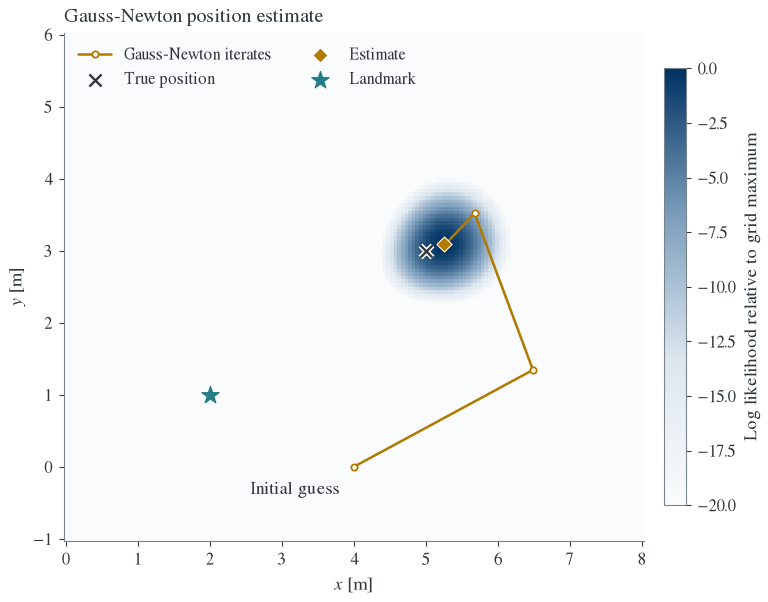

In [8]:
# Plot the stored iterates on the original likelihood grid.
fig, ax = plt.subplots(figsize=(6.5, 4.6), layout='constrained')
im = ax.pcolormesh(xs, ys, LL - LL.max(), shading='nearest',
                   cmap=likelihood_colors, rasterized=True, vmin=-20, vmax=0)
ax.plot(hist[:,0], hist[:,1], color=GOLD, marker='o', markersize=3.5,
        markerfacecolor='white', label='Gauss-Newton iterates')
ax.scatter(*x_true, marker='x', s=45, color='white', linewidth=3.0, zorder=6)
ax.scatter(*x_true, marker='x', s=45, color=INK, linewidth=1.3,
           zorder=6, label='True position')
ax.scatter(*x_hat, marker='D', s=35, color=GOLD, edgecolor='white',
           linewidth=0.6, zorder=6, label='Estimate')
ax.scatter(*ell, marker='*', s=100, color=TEAL, label='Landmark')
ax.annotate('Initial guess', hist[0], xytext=(-8,-15),
            textcoords='offset points', ha='right')
ax.set(xlabel='$x$ [m]', ylabel='$y$ [m]', aspect='equal')
ax.set_title('Gauss-Newton position estimate', loc='left')
ax.legend(loc='upper left', ncol=2)
colorbar = fig.colorbar(im, ax=ax, shrink=0.86, pad=0.025)
colorbar.set_label('Log likelihood relative to grid maximum')
fig.savefig('../figures/sensor-models-gauss-newton.pdf', bbox_inches='tight')
fig.savefig('../figures/sensor-models-gauss-newton.png', dpi=240, bbox_inches='tight')
plt.show()

## 4) Observability check (local)

For a measurement model $\mathbf{z}=h(\mathbf{x})$, local observability of the **state components** (at a point) is related to the rank of the Jacobian $H = \partial h / \partial \mathbf{x}$.

Here we compare:
- Range-only to one landmark
- Bearing-only to one landmark
- Range+bearing to one landmark
- Range-only to **two** landmarks

In [9]:
def H_range(xy, ell):
    return jacobian_range(xy, ell).reshape(1,2)

def H_bearing(xy, ell):
    return jacobian_bearing(xy, ell).reshape(1,2)

def rank(A, tol=1e-10):
    return np.linalg.matrix_rank(A, tol=tol)

xy0 = np.array([5.0, 3.0])
ell1 = np.array([2.0, 1.0])
ell2 = np.array([1.0, 5.0])

cases = {
    "range-only (1 landmark)": H_range(xy0, ell1),
    "bearing-only (1 landmark)": H_bearing(xy0, ell1),
    "range+bearing (1 landmark)": np.vstack([H_range(xy0, ell1), H_bearing(xy0, ell1)]),
    "range-only (2 landmarks)": np.vstack([H_range(xy0, ell1), H_range(xy0, ell2)]),
}

for k, H in cases.items():
    print(f"{k:28s}  H shape={H.shape}  rank(H)={rank(H)}")

range-only (1 landmark)       H shape=(1, 2)  rank(H)=1
bearing-only (1 landmark)     H shape=(1, 2)  rank(H)=1
range+bearing (1 landmark)    H shape=(2, 2)  rank(H)=2
range-only (2 landmarks)      H shape=(2, 2)  rank(H)=2


**Interpretation:**  
- One range measurement gives a **circle** of possible $(x,y)$ ⇒ rank 1.  
- One bearing measurement gives a **ray** of possible $(x,y)$ ⇒ rank 1.  
- Range+bearing to one landmark generally pins down $(x,y)$ locally ⇒ rank 2 (except for degenerate configurations).  
- Two independent range measurements to different landmarks can also give rank 2.

## 5) Minimal camera projection model (pinhole)

World point in camera frame:
$\mathbf{p} = \begin{bmatrix}X\\Y\\Z\end{bmatrix},\quad Z>0$

Normalized image coordinates:
$u_n = X/Z,\qquad v_n = Y/Z$

Pixel coordinates (intrinsics: $f_x,f_y,c_x,c_y$):
$u = f_x u_n + c_x,\qquad v = f_y v_n + c_y$

Note: Intrinsics (or camera intrinsics) refer to the set of parameters that describe the internal geometry and optics of a camera, i.e., how 3D rays entering the lens are mapped to pixel coordinates on the image sensor.

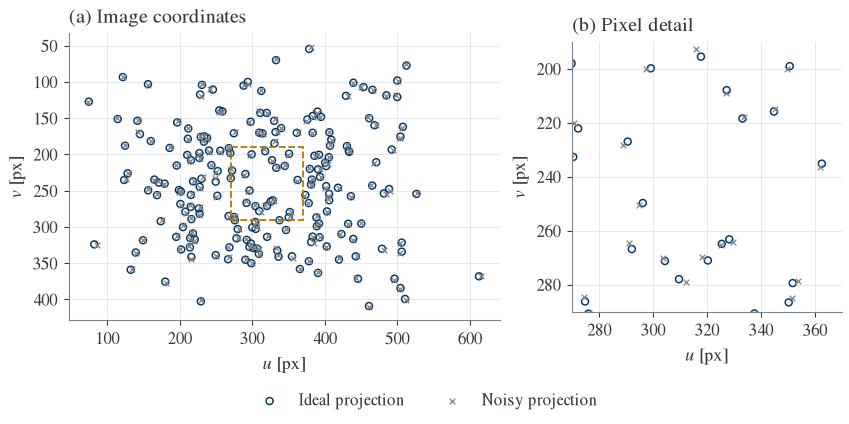

In [10]:
def project_pinhole(P, fx=600.0, fy=600.0, cx=320.0, cy=240.0):
    X, Y, Z = P[...,0], P[...,1], P[...,2]
    u = fx*(X/Z) + cx
    v = fy*(Y/Z) + cy
    return np.stack([u, v], axis=-1)

# Simulate a cube of 3D points in front of the camera
n = 200
P = np.column_stack([
    np.random.uniform(-1.0, 1.0, n),   # X
    np.random.uniform(-0.7, 0.7, n),   # Y
    np.random.uniform(2.0, 5.0, n)     # Z
])

uv = project_pinhole(P)
sigma_px = 1.5
uv_noisy = uv + np.random.randn(*uv.shape)*sigma_px

# Both panels use the original projected points and noise realization.
fig, axes = plt.subplots(1, 2, figsize=(6.5, 3.5), layout='constrained',
                         gridspec_kw={'width_ratios':[1.6,1]})
for ax in axes:
    ax.scatter(uv[:,0], uv[:,1], s=15, facecolors='none', edgecolors=BLUE,
               linewidths=0.8, label='Ideal projection')
    ax.scatter(uv_noisy[:,0], uv_noisy[:,1], s=10, marker='x', color=GRAY,
               linewidths=0.7, label='Noisy projection')
    ax.set(xlabel='$u$ [px]', ylabel='$v$ [px]', aspect='equal')
    ax.invert_yaxis()
    ax.grid(linewidth=0.45)
axes[0].add_patch(Rectangle((270,190),100,100,fill=False,edgecolor=GOLD,
                            linewidth=1.0,linestyle='--'))
axes[0].set_title('(a) Image coordinates',loc='left')
fig.legend(*axes[0].get_legend_handles_labels(), loc='outside lower center', ncol=2)
axes[1].set(xlim=(270,370),ylim=(290,190))
axes[1].set_title('(b) Pixel detail',loc='left')
fig.savefig('../figures/sensor-models-camera.pdf', bbox_inches='tight')
fig.savefig('../figures/sensor-models-camera.png', dpi=240, bbox_inches='tight')
plt.show()

## 6) What to modify for your own examples

- Change `ell` and `x_true` to match your scenario (e.g., a robot moving past multiple landmarks).
- Extend to **range-only** or **bearing-only** filtering by using the relevant likelihood function.
- Add a **robot heading** $\psi$ and define a bearing model relative to body frame, e.g.,
$\,z_\theta = \mathrm{wrap}(\operatorname{atan2}(y-\ell_y,x-\ell_x)-\psi)+v$.
- For camera models, add **extrinsics** (rotation+translation) before projection.